# News Data Split

This notebook randomly splits all records in `data/processed/final.jsonl` into:

- 80% training records
- 10% validation records
- 10% test records

The split is reproducible and each input record appears in exactly one output file.

## Setup

In [1]:
import os
import json
import pandas as pd

PROCESSED_DIR = "data/processed"
INPUT_PATH = os.path.join(PROCESSED_DIR, "final.jsonl")
TRAIN_PATH = os.path.join(PROCESSED_DIR, "train.jsonl")
VAL_PATH = os.path.join(PROCESSED_DIR, "validation.jsonl")
TEST_PATH = os.path.join(PROCESSED_DIR, "test.jsonl")

TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1
SEED = 42

assert TRAIN_RATIO + VAL_RATIO + TEST_RATIO == 1.0

## Load processed records

In [2]:
if not os.path.exists(INPUT_PATH):
    raise FileNotFoundError(
        f"Could not find '{INPUT_PATH}'. Create the final processed dataset first."
    )

records = []
with open(INPUT_PATH, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            records.append(json.loads(line))

processed_df = pd.DataFrame(records)
if processed_df.empty:
    raise ValueError(f"No records were found in '{INPUT_PATH}'.")
if "article_id" not in processed_df.columns:
    raise ValueError("The processed dataset must contain an 'article_id' column.")
if processed_df["article_id"].duplicated().any():
    raise ValueError("The processed dataset contains duplicate article IDs.")

print(f"Loaded {len(processed_df)} records")

Loaded 500 records


## Create disjoint train, validation and test sets

In [3]:
shuffled_df = processed_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

total_records = len(shuffled_df)
train_size = int(total_records * TRAIN_RATIO)
val_size = int(total_records * VAL_RATIO)
train_end = train_size
val_end = train_end + val_size

train_df = shuffled_df.iloc[:train_end].copy().reset_index(drop=True)
val_df = shuffled_df.iloc[train_end:val_end].copy().reset_index(drop=True)
test_df = shuffled_df.iloc[val_end:].copy().reset_index(drop=True)

# Leakage checks.
assert set(train_df["article_id"]).isdisjoint(val_df["article_id"])
assert set(train_df["article_id"]).isdisjoint(test_df["article_id"])
assert set(val_df["article_id"]).isdisjoint(test_df["article_id"])
assert len(train_df) + len(val_df) + len(test_df) == total_records

print(f"Train:      {len(train_df)} records ({len(train_df) / total_records:.0%})")
print(f"Validation: {len(val_df)} records ({len(val_df) / total_records:.0%})")
print(f"Test:       {len(test_df)} records ({len(test_df) / total_records:.0%})")

Train:      400 records (80%)
Validation: 50 records (10%)
Test:       50 records (10%)


## Analyze original aspect labels

This section evaluates the original labelled samples before fine-tuning.

It checks every article against the seven required aspect labels:

- Event
- People
- Organization
- Date & Time
- Location
- Effects
- Countermeasures

For each article and each aspect, the value is classified as `Stated` or `Not stated`. The analysis also summarizes the distribution for the full dataset and separately for the training, validation and test splits. This helps identify label imbalance, especially when a model learns to over-predict `Not stated`.

In [4]:
ASPECT_LABELS = {
    "event": "Event",
    "people": "People",
    "organization": "Organization",
    "date_time": "Date & Time",
    "location": "Location",
    "causes": "Causes",
    "effects": "Effects",
    "countermeasures": "Countermeasures",
}

def validate_aspects(df: pd.DataFrame, split_name: str):
    if "aspects" not in df.columns:
        raise ValueError(f"{split_name} does not contain an 'aspects' column.")

    for index, row in df.iterrows():
        aspects = row["aspects"]

        if not isinstance(aspects, dict):
            raise ValueError(
                f"{split_name} article {row['article_id']} has an invalid aspects value."
            )

        missing = [key for key in ASPECT_LABELS if key not in aspects]
        if missing:
            raise ValueError(
                f"{split_name} article {row['article_id']} is missing aspects: {missing}"
            )

        blank = [
            key for key in ASPECT_LABELS
            if str(aspects[key]).strip() == ""
        ]
        if blank:
            raise ValueError(
                f"{split_name} article {row['article_id']} has blank aspects: {blank}"
            )

validate_aspects(train_df, "Training")
validate_aspects(val_df, "Validation")
validate_aspects(test_df, "Test")

print("Aspect validation passed for all samples.")

Aspect validation passed for all samples.


In [5]:
def aspect_status(value) -> str:
    normalized = " ".join(str(value).strip().lower().split())
    return "Not stated" if normalized == "not stated" else "Stated"

def build_sample_aspect_status(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    rows = []

    for _, row in df.iterrows():
        for key, label in ASPECT_LABELS.items():
            value = str(row["aspects"][key]).strip()

            rows.append({
                "article_id": row["article_id"],
                "split": split_name,
                "aspect_key": key,
                "aspect_label": label,
                "aspect_value": value,
                "status": aspect_status(value),
            })

    return pd.DataFrame(rows)

sample_aspect_status_df = pd.concat(
    [
        build_sample_aspect_status(train_df, "Training"),
        build_sample_aspect_status(val_df, "Validation"),
        build_sample_aspect_status(test_df, "Test"),
    ],
    ignore_index=True,
)

sample_status_wide_df = (
    sample_aspect_status_df
    .pivot(
        index=["article_id", "split"],
        columns="aspect_label",
        values="status",
    )
    .reset_index()
)

status_columns = list(ASPECT_LABELS.values())
sample_status_wide_df["Stated Count"] = (
    sample_status_wide_df[status_columns] == "Stated"
).sum(axis=1)
sample_status_wide_df["Not stated Count"] = (
    sample_status_wide_df[status_columns] == "Not stated"
).sum(axis=1)

print("Per-sample aspect status:")
display(sample_status_wide_df.head(20))

Per-sample aspect status:


aspect_label,article_id,split,Causes,Countermeasures,Date & Time,Effects,Event,Location,Organization,People,Stated Count,Not stated Count
0,0053278402828d9c471a1df7a93593a32f614a24,Training,Not stated,Not stated,Not stated,Stated,Stated,Stated,Not stated,Stated,4,4
1,008cccedbf17904f04ced8aebb894ed0ded94904,Training,Not stated,Stated,Not stated,Stated,Stated,Stated,Not stated,Not stated,4,4
2,0129aa6c6f670ce0728c24ef8d4bea7a3b4dfec4,Training,Stated,Not stated,Not stated,Stated,Stated,Stated,Not stated,Stated,5,3
3,021737af5caf5536ade0f41b2d5a8ce5fd26b421,Training,Stated,Not stated,Not stated,Not stated,Stated,Stated,Not stated,Not stated,3,5
4,0217d3e2127ec64fb73a37ef8f802ea4f2e26dc3,Training,Stated,Not stated,Stated,Not stated,Stated,Not stated,Not stated,Not stated,3,5
5,0272289e4d143513fd4e829a98a1d66099903221,Training,Stated,Stated,Not stated,Stated,Stated,Stated,Not stated,Stated,6,2
6,03190726f4af805cbaa0270216669a9c2b5298a1,Training,Not stated,Stated,Not stated,Stated,Stated,Not stated,Not stated,Stated,4,4
7,03d25219690b52111f3f7f19c5bf248d5cb92b7c,Training,Stated,Not stated,Stated,Stated,Stated,Stated,Not stated,Not stated,5,3
8,05914c9c261d1be845fcf666dc02d85432d5ff4f,Training,Not stated,Stated,Not stated,Not stated,Stated,Stated,Stated,Stated,5,3
9,06a6b5a60066a92f262a7472ccea56408dd31659,Training,Stated,Stated,Not stated,Stated,Stated,Stated,Not stated,Stated,6,2


In [6]:
def summarize_aspect_status(status_df: pd.DataFrame, group_columns: list) -> pd.DataFrame:
    summary = (
        status_df
        .groupby(group_columns + ["status"])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )

    if "Stated" not in summary.columns:
        summary["Stated"] = 0
    if "Not stated" not in summary.columns:
        summary["Not stated"] = 0

    summary["Total"] = summary["Stated"] + summary["Not stated"]
    summary["Stated %"] = summary["Stated"] / summary["Total"] * 100
    summary["Not stated %"] = summary["Not stated"] / summary["Total"] * 100

    return summary

overall_aspect_summary_df = summarize_aspect_status(
    sample_aspect_status_df,
    ["aspect_label"],
)

split_aspect_summary_df = summarize_aspect_status(
    sample_aspect_status_df,
    ["split", "aspect_label"],
)

training_aspect_summary_df = (
    split_aspect_summary_df[
        split_aspect_summary_df["split"] == "Training"
    ]
    .copy()
    .reset_index(drop=True)
)

print("Overall original-sample aspect distribution:")
display(overall_aspect_summary_df)

print("Original training-sample aspect distribution:")
display(training_aspect_summary_df)

print("Distribution by split:")
display(split_aspect_summary_df)

Overall original-sample aspect distribution:


status,aspect_label,Not stated,Stated,Total,Stated %,Not stated %
0,Causes,256,244,500,48.8,51.2
1,Countermeasures,332,168,500,33.6,66.4
2,Date & Time,391,109,500,21.8,78.2
3,Effects,263,237,500,47.4,52.6
4,Event,0,500,500,100.0,0.0
5,Location,53,447,500,89.4,10.6
6,Organization,354,146,500,29.2,70.8
7,People,182,318,500,63.6,36.4


Original training-sample aspect distribution:


status,split,aspect_label,Not stated,Stated,Total,Stated %,Not stated %
0,Training,Causes,201,199,400,49.75,50.25
1,Training,Countermeasures,260,140,400,35.00,65.00
2,Training,Date & Time,309,91,400,22.75,77.25
3,Training,Effects,204,196,400,49.00,51.00
4,Training,Event,0,400,400,100.00,0.00
5,Training,Location,42,358,400,89.50,10.50
6,Training,Organization,289,111,400,27.75,72.25
7,Training,People,137,263,400,65.75,34.25


Distribution by split:


status,split,aspect_label,Not stated,Stated,Total,Stated %,Not stated %
0,Test,Causes,27,23,50,46.00,54.00
1,Test,Countermeasures,32,18,50,36.00,64.00
2,Test,Date & Time,45,5,50,10.00,90.00
3,Test,Effects,24,26,50,52.00,48.00
4,Test,Event,0,50,50,100.00,0.00
5,Test,Location,6,44,50,88.00,12.00
6,Test,Organization,34,16,50,32.00,68.00
7,Test,People,22,28,50,56.00,44.00
8,Training,Causes,201,199,400,49.75,50.25
9,Training,Countermeasures,260,140,400,35.00,65.00


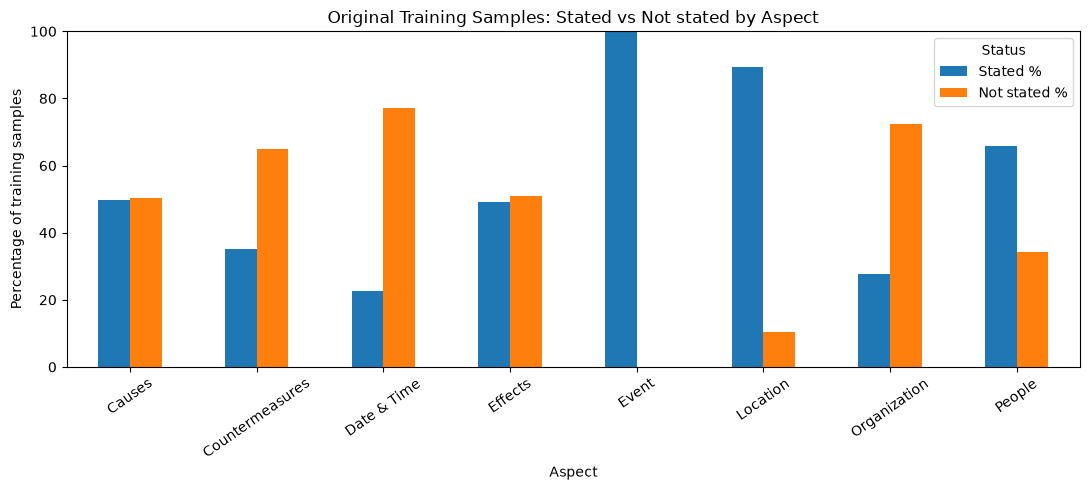

In [7]:
import matplotlib.pyplot as plt

plot_df = training_aspect_summary_df.set_index("aspect_label")[
    ["Stated %", "Not stated %"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5),
)

ax.set_title("Original Training Samples: Stated vs Not stated by Aspect")
ax.set_xlabel("Aspect")
ax.set_ylabel("Percentage of training samples")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Status")
plt.tight_layout()
plt.show()

### How to interpret the analysis

A high `Not stated %` means that the model sees that label frequently during fine-tuning. If `Effects` or `Countermeasures` contain `Not stated` much more often than real values, the model may learn that `Not stated` is a safe prediction.

The train, validation and test distributions should also be reasonably similar. Large differences between splits can make validation or test results less representative of what the model learned during training.

## Save splits

In [8]:
def save_jsonl(df: pd.DataFrame, path: str):
    with open(path, "w", encoding="utf-8") as f:
        for record in df.to_dict(orient="records"):
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    print(f"Saved {len(df)} rows to '{path}'")


save_jsonl(train_df, TRAIN_PATH)
save_jsonl(val_df, VAL_PATH)
save_jsonl(test_df, TEST_PATH)

Saved 400 rows to 'data/processed\train.jsonl'
Saved 50 rows to 'data/processed\validation.jsonl'
Saved 50 rows to 'data/processed\test.jsonl'
